In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    classification_report
)

import lightgbm as lgb
from catboost import CatBoostClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from src.data.load import load_data
from src.features.build import transform_features, build_preprocessor

RANDOM_STATE = 42

/tmp/ipykernel_5815/4178774849.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [3]:
df = transform_features(load_data())

X = df.drop(columns=['default.payment.next.month'])
y = df['default.payment.next.month']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}, churn rate: {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}, churn rate: {y_test.mean():.3f}")



Train: (24000, 19), churn rate: 0.221
Test:  (6000, 19), churn rate: 0.221


In [4]:
def evaluate_model(name, model, X_test, y_test):
    proba = model.predict_proba(X_test)[:, 1]
    preds = (proba > 0.5).astype(int)

    top_10_idx = np.argsort(proba)[::-1][:int(len(proba) * 0.1)]
    recall_at_10 = y_test.iloc[top_10_idx].mean()

    return {
        "model": name,
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "f1": f1_score(y_test, preds),
        "recall@10%": recall_at_10,
    }

In [5]:
def objective(trial):
    solver = trial.suggest_categorical("solver", ["lbfgs", "saga"])
    if solver == "lbfgs":
        penalty = "l2"
    else:
        penalty = trial.suggest_categorical("penalty", ["l1", "l2"])

    params = {
        "C": trial.suggest_float("C", 1e-3, 100, log=True),
        "solver": solver,
        "penalty": penalty,
        "max_iter": 1000,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
    }

    pipeline = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(**params)),
    ])

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    return scores.mean()


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=25, show_progress_bar=True)

print(f"Best ROC-AUC: {study.best_value:.4f}")
print(f"Best params:  {study.best_params}")

Best trial: 1. Best value: 0.754878:   8%|▊         | 2/25 [00:01<00:21,  1.07it/s]/home/nikitos/MLSystem/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/nikitos/MLSystem/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/nikitos/MLSystem/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/nikitos/MLSystem/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/nikitos/MLSystem/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means t

Best ROC-AUC: 0.7549
Best params:  {'solver': 'saga', 'penalty': 'l2', 'C': 9.394196918782772}


In [6]:
logReg = Pipeline(steps=[
    ("preprocessor", build_preprocessor()),
    ("model", LogisticRegression(
        **study.best_params,
        max_iter=1000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ))
])
logReg.fit(X_train, y_train)
lr_metrics = evaluate_model('LogisticRegression', logReg, X_test, y_test)
print(lr_metrics)

{'model': 'LogisticRegression', 'roc_auc': 0.7402580941259986, 'pr_auc': 0.4403992687617374, 'f1': 0.5022209061297009, 'recall@10%': 0.5}


In [7]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 500, step=50),
        "max_depth": trial.suggest_int("max_depth", 10, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 5),
        "max_features": trial.suggest_categorical("max_features", ['sqrt', 'log2', None]),
        "class_weight": 'balanced',
        "random_state": RANDOM_STATE
    }

    model = RandomForestClassifier(**params)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    return scores.mean()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"Best ROC-AUC: {study.best_value:.4f}")
print(f"Best params:  {study.best_params}") 

Best trial: 11. Best value: 0.772704: 100%|██████████| 50/50 [12:37<00:00, 15.16s/it]

Best ROC-AUC: 0.7727
Best params:  {'n_estimators': 400, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'log2'}


In [8]:
rf = RandomForestClassifier(**study.best_params, class_weight='balanced', random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
rf_metrics = evaluate_model("RandomForest", rf, X_test, y_test)
print(rf_metrics)

{'model': 'RandomForest', 'roc_auc': 0.7623745962592592, 'pr_auc': 0.4943730481779289, 'f1': 0.5237639553429028, 'recall@10%': 0.5833333333333334}


In [9]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
        "verbose": -1,
    }

    model = lgb.LGBMClassifier(**params)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    return scores.mean()


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"Best ROC-AUC: {study.best_value:.4f}")
print(f"Best params:  {study.best_params}")

Best trial: 37. Best value: 0.77329: 100%|██████████| 50/50 [24:10<00:00, 29.02s/it] 

Best ROC-AUC: 0.7733
Best params:  {'n_estimators': 450, 'max_depth': 6, 'learning_rate': 0.008573284834129728, 'num_leaves': 29, 'min_child_samples': 19, 'subsample': 0.8397151514472229, 'colsample_bytree': 0.7423037751345191, 'reg_alpha': 0.0018604271097014996, 'reg_lambda': 0.7526859917125899}


In [10]:
lgbm = lgb.LGBMClassifier(**study.best_params, class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)
lgbm.fit(X_train, y_train)
lgbm_metrics = evaluate_model("LightGBM", lgbm, X_test, y_test)
print(lgbm_metrics)

{'model': 'LightGBM', 'roc_auc': 0.7653733524418604, 'pr_auc': 0.49627893409735446, 'f1': 0.5186972255729795, 'recall@10%': 0.5866666666666667}


In [11]:


def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 100, 1000, step=50),
        "depth": trial.suggest_int("depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "l2_leaf_reg": trial.suggest_int("l2_leaf_reg", 1, 10),
        "random_strength": trial.suggest_int("random_strength", 1, 10),
        "auto_class_weights": "Balanced",
        "random_state": RANDOM_STATE,
        "verbose": 0,
    }

    model = CatBoostClassifier(**params)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    return scores.mean()


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"Best ROC-AUC: {study.best_value:.4f}")
print(f"Best params:  {study.best_params}")



Best trial: 47. Best value: 0.773693: 100%|██████████| 50/50 [04:32<00:00,  5.45s/it]

Best ROC-AUC: 0.7737
Best params:  {'iterations': 1000, 'depth': 6, 'learning_rate': 0.015380591654876225, 'l2_leaf_reg': 4, 'random_strength': 10}


In [12]:
catboost = CatBoostClassifier(**study.best_params, auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=False)
catboost.fit(X_train, y_train)
catboost_metrics = evaluate_model("CatBoost", catboost, X_test, y_test)
print(catboost_metrics)

{'model': 'CatBoost', 'roc_auc': 0.764576635229624, 'pr_auc': 0.49030430274913994, 'f1': 0.5186522262334536, 'recall@10%': 0.5783333333333334}


In [13]:
for name, model in [('LogisticRegression', logReg), ('RandomForest', rf), ('LightGBM', lgbm), ('CatBoost', catboost)]:
    train_proba = model.predict_proba(X_train)[:, -1]
    test_proba = model.predict_proba(X_test)[:, -1]
    train_auc = roc_auc_score(y_train, train_proba)
    test_auc = roc_auc_score(y_test, test_proba)
    print(f'{name}: train: {train_auc:.4f}, test: {test_auc:.4f}, gap: {train_auc - test_auc:.4f}')

LogisticRegression: train: 0.7572, test: 0.7403, gap: 0.0169
RandomForest: train: 0.8683, test: 0.7624, gap: 0.1059
LightGBM: train: 0.8152, test: 0.7654, gap: 0.0499
CatBoost: train: 0.8142, test: 0.7646, gap: 0.0496


In [14]:
def bootstrap_auc(y_true, y_proba, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        scores.append(roc_auc_score(y_true.iloc[idx], y_proba[idx]))
    scores = np.array(scores)
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

lr_proba = logReg.predict_proba(X_test)[:, 1]
rf_proba = rf.predict_proba(X_test)[:, 1]
cat_proba = catboost.predict_proba(X_test)[:, 1]
lgb_proba = lgbm.predict_proba(X_test)[:, 1]

for name, proba in [("LogReg", lr_proba), ("RandomForest", rf_proba), ("CatBoost", cat_proba), ("LightGBM", lgb_proba)]:
    mean, std, ci = bootstrap_auc(y_test, proba)
    print(f"{name:12} ROC-AUC: {mean:.4f} ± {std:.4f}, 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]")

LogReg       ROC-AUC: 0.7405 ± 0.0078, 95% CI: [0.7258, 0.7563]
RandomForest ROC-AUC: 0.7625 ± 0.0074, 95% CI: [0.7478, 0.7776]
CatBoost     ROC-AUC: 0.7647 ± 0.0074, 95% CI: [0.7506, 0.7798]
LightGBM     ROC-AUC: 0.7656 ± 0.0074, 95% CI: [0.7507, 0.7812]


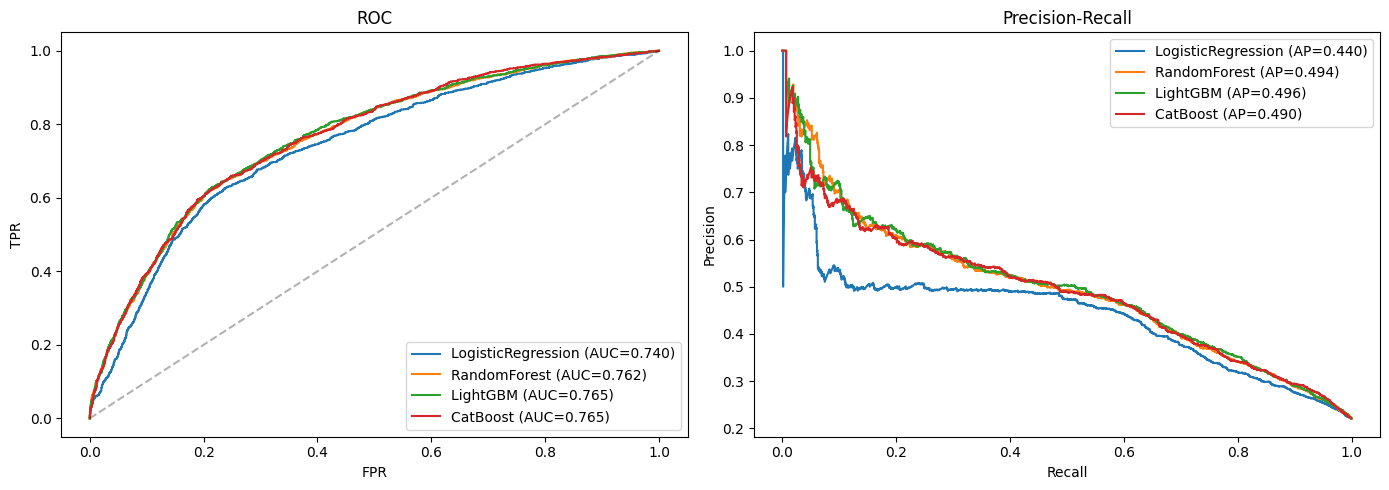

In [15]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, model in [
    ("LogisticRegression", logReg),
    ("RandomForest", rf),
    ("LightGBM", lgbm),
    ("CatBoost", catboost),
]:
    proba = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC")
axes[0].legend()

axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall"); axes[1].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "roc_pr_curves.png",
            dpi=100, bbox_inches="tight")
plt.show()

Optimal threshold: 0.43
Expected profit:   $60,495,000


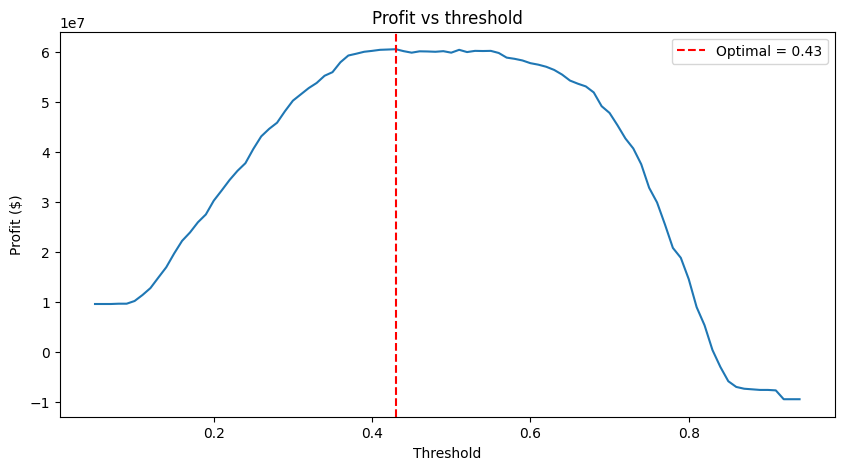

In [16]:
AVG_LOAN_AMOUNT = 100_000
LGD = 0.6
PROFIT_RATE = 0.15
LOSS_GIVEN_DEFAULT = AVG_LOAN_AMOUNT * LGD
PROFIT_GIVEN_GOOD = AVG_LOAN_AMOUNT * PROFIT_RATE

proba = lgbm.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.05, 0.95, 0.01)
profits = []

for thr in thresholds:
    preds = (proba > thr).astype(int)
    tp = ((preds == 1) & (y_test == 1)).sum()
    fp = ((preds == 1) & (y_test == 0)).sum()
    tn = ((preds == 0) & (y_test == 0)).sum()
    fn = ((preds == 0) & (y_test == 1)).sum()
    profit = (tn - fp) * PROFIT_GIVEN_GOOD + (tp - fn) * LOSS_GIVEN_DEFAULT
    profits.append(profit)

profits = np.array(profits)
best_thr = thresholds[profits.argmax()]
best_profit = profits.max()

print(f"Optimal threshold: {best_thr:.2f}")
print(f"Expected profit:   ${best_profit:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(thresholds, profits)
plt.axvline(best_thr, color="red", linestyle="--", label=f"Optimal = {best_thr:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Profit ($)")
plt.title("Profit vs threshold"); plt.legend()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "threshold_optimization.png",
            dpi=100, bbox_inches="tight")
plt.show()

Confusion Matrix:
[[3207 1466]
 [ 377  950]]

Classification Report:
              precision    recall  f1-score   support

  No default       0.89      0.69      0.78      4673
     default       0.39      0.72      0.51      1327

    accuracy                           0.69      6000
   macro avg       0.64      0.70      0.64      6000
weighted avg       0.78      0.69      0.72      6000



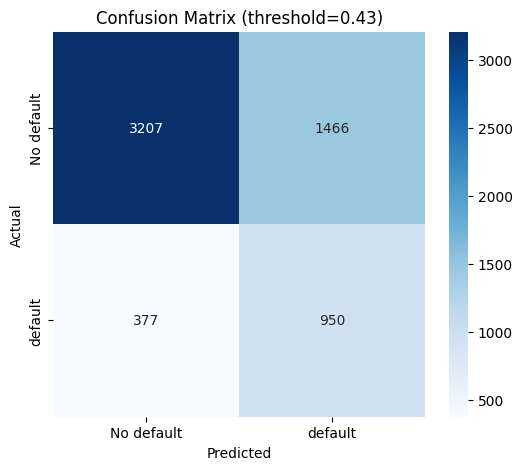

In [17]:
final_preds = (proba > best_thr).astype(int)

cm = confusion_matrix(y_test, final_preds)
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, final_preds, target_names=["No default", "default"]))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No default", "default"],
            yticklabels=["No default", "default"])
plt.ylabel("Actual"); plt.xlabel("Predicted")
plt.title(f"Confusion Matrix (threshold={best_thr:.2f})")
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "confusion_matrix.png",
            dpi=100, bbox_inches="tight")
plt.show()


In [18]:
import json
import joblib
from pathlib import Path
from datetime import datetime
from sklearn.metrics import roc_auc_score, average_precision_score

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(lgbm, MODELS_DIR / "default_pipeline.pkl")

metadata = {
    "model": "LightGBM",
    "version": "1.0",
    "trained_at": datetime.now().isoformat(),
    "reason": "Лучший test ROC-AUC + минимальный gap + статистически не отличается от CatBoost и RandomForest",
    "metrics": {
        "roc_auc": float(roc_auc_score(y_test, proba)),
        "pr_auc": float(average_precision_score(y_test, proba)),
        "optimal_threshold": float(best_thr),
        "expected_profit": float(best_profit),
    },
    "comparison": {
        "LogisticRegression": {"test_roc_auc": 0.7403, "gap": 0.0169},
        "CatBoost": {"test_roc_auc": 0.7646, "gap": 0.04},
        "LightGBM": {"test_roc_auc": 0.7654, "gap": 0.0478},
        "RandomForest": {"test_roc_auc": 0.7624, "gap": 0.0948}
    },
    "hyperparams": lgbm.get_params(),
}

with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "model": "LightGBM",
  "version": "1.0",
  "trained_at": "2026-10-12T21:32:29.489616",
  "reason": "Лучший test ROC-AUC + минимальный gap + статистически не отличается от CatBoost и RandomForest",
  "metrics": {
    "roc_auc": 0.7653733524418604,
    "pr_auc": 0.49627893409735446,
    "optimal_threshold": 0.43000000000000005,
    "expected_profit": 60495000.0
  },
  "comparison": {
    "LogisticRegression": {
      "test_roc_auc": 0.7403,
      "gap": 0.0169
    },
    "CatBoost": {
      "test_roc_auc": 0.7646,
      "gap": 0.04
    },
    "LightGBM": {
      "test_roc_auc": 0.7654,
      "gap": 0.0478
    },
    "RandomForest": {
      "test_roc_auc": 0.7624,
      "gap": 0.0948
    }
  },
  "hyperparams": {
    "boosting_type": "gbdt",
    "class_weight": "balanced",
    "colsample_bytree": 0.7423037751345191,
    "importance_type": "split",
    "learning_rate": 0.008573284834129728,
    "max_depth": 6,
    "min_child_samples": 19,
    "min_child_weight": 0.001,
    "min_split_g